In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/real_estate_cleaned.csv', parse_dates=['date'])
df['zipcode'] = df['zipcode'].astype(str)

num_cols = ['sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'floors', 'view',
            'condition', 'waterfront', 'sqft_above', 'sqft_basement',
            'house_age', 'has_basement', 'was_renovated']
cat_cols = ['zipcode']

X = df[num_cols + cat_cols].copy()
y = df['price']


for c in ['sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement']:
    X[c] = np.log1p(X[c])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [2]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=5), cat_cols),
])

models = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

fitted = {}
for name, m in models.items():
    fitted[name] = Pipeline([('pre', pre), ('model', m)]).fit(X_train, np.log1p(y_train))

In [3]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

for name, p in fitted.items():
    pred = np.expm1(p.predict(X_test))          
    print(f"{name:18s} R2={r2_score(y_test, pred):.3f}  "
          f"MAE=${mean_absolute_error(y_test, pred):,.0f}  "
          f"RMSE=${np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

Ridge              R2=0.850  MAE=$85,788  RMSE=$145,475
Random Forest      R2=0.706  MAE=$112,237  RMSE=$203,517
Gradient Boosting  R2=0.708  MAE=$114,615  RMSE=$202,650


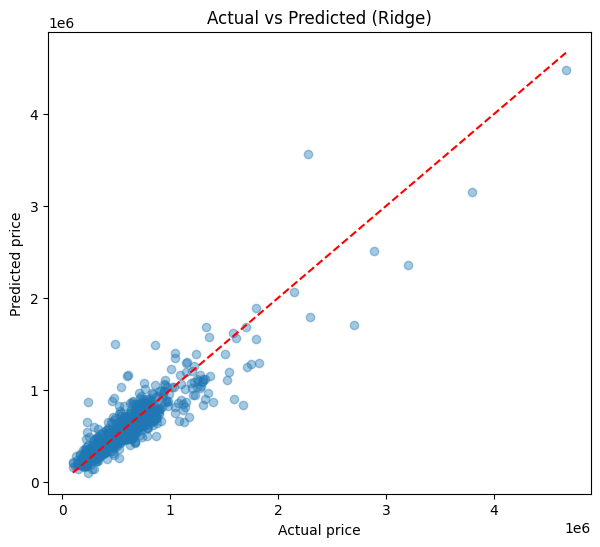

sqft_above       0.152533
sqft_living      0.145035
view             0.057006
bathrooms        0.045719
sqft_lot         0.044404
condition        0.040335
bedrooms        -0.033135
has_basement     0.030120
waterfront       0.028958
floors          -0.012406
was_renovated    0.010938
house_age       -0.009443
sqft_basement   -0.006995
dtype: float64


In [4]:
import matplotlib.pyplot as plt

best = fitted['Ridge']
pred = np.expm1(best.predict(X_test))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred, alpha=0.4)
lim = [y_test.min(), y_test.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('Actual price'); plt.ylabel('Predicted price')
plt.title('Actual vs Predicted (Ridge)')
plt.show()


coefs = pd.Series(best.named_steps['model'].coef_[:len(num_cols)], index=num_cols)
print(coefs.sort_values(key=abs, ascending=False))